## **1. Carga del dataset**

Vamos a cargar las imágenes del dataset, asegurándonos de que todas tengan la misma resolución y estén en escala de grises.

In [11]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [12]:
DATASET_DIR = "data/images"
IMG_SIZE = 64
TOTAL_IMAGES = 30000

images = np.empty((TOTAL_IMAGES, IMG_SIZE, IMG_SIZE), dtype=np.uint8)

In [13]:
loaded_count = 0

for i in range(TOTAL_IMAGES):
    filename = f"{i}.jpg"
    filepath = os.path.join(DATASET_DIR, filename)
    
    # Lectura en escala de grises (se evalua en grises)
    img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
    
    if img is None:
        raise FileNotFoundError(f"No se pudo cargar la imagen: {filepath}")
    
    # Garantizamos resolución de 64x64 
    if img.shape != (IMG_SIZE, IMG_SIZE):
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
        
    images[i] = img
    loaded_count += 1

print(f"Total cargado: {loaded_count} imágenes")

Total cargado: 30000 imágenes


In [14]:
# Comprobaciones numéricas y dimensionales
print(f"Forma del tensor: {images.shape}")          # Esperado: (30000, 64, 64)
print(f"Tipo de dato:     {images.dtype}")          # Esperado: uint8
print(f"Valor mínimo:     {images.min()}")          # Esperado: 0 o cercano 
print(f"Valor máximo:     {images.max()}")          # Esperado: 255 o cercano 

Forma del tensor: (30000, 64, 64)
Tipo de dato:     uint8
Valor mínimo:     0
Valor máximo:     255


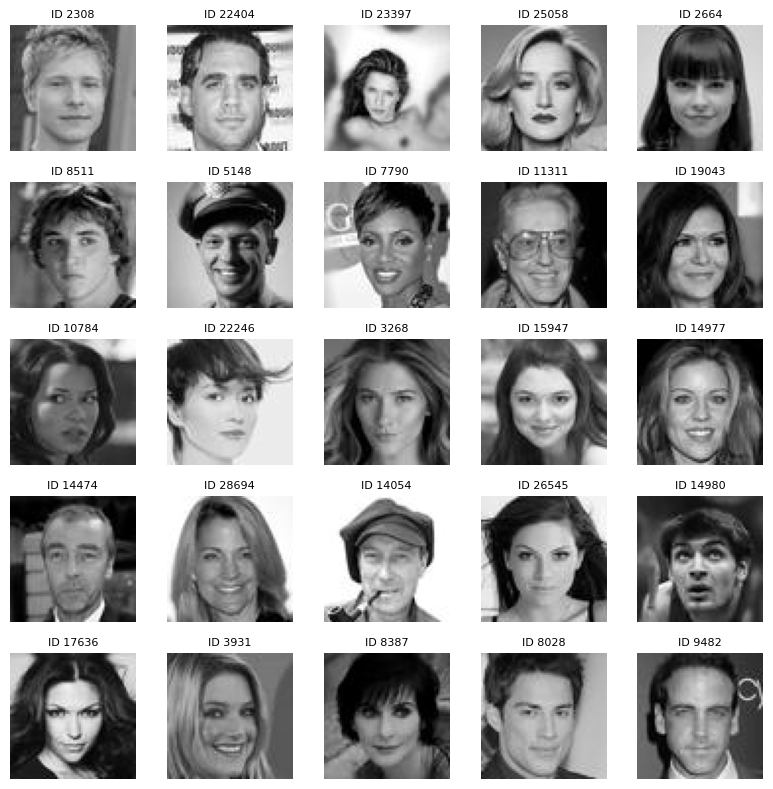

In [ ]:
# Visualización de una cuadrícula de 5x5 imágenes
fig, axes = plt.subplots(5, 5, figsize=(8, 8))
np.random.seed(42)
sample_indices = np.random.choice(TOTAL_IMAGES, size=25, replace=False)

for ax, idx in zip(axes.flat, sample_indices):
    ax.imshow(images[idx], cmap="gray", vmin=0, vmax=255)
    ax.axis("off")
    ax.set_title(f"ID {idx}", fontsize=8)

plt.tight_layout()
plt.show()

---

## **2. Implementación del AE Baseline**

In [16]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

In [17]:
# Semillas para reproducibilidad
SEED = 1234
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [18]:
# Preprocesamiento y split (90% Train / 10% Val)

x_data = images.astype("float32") / 255.0
x_data = np.expand_dims(x_data, axis=-1)  # (30000, 64, 64, 1)

val_size = int(0.10 * len(x_data))
indices = np.random.permutation(len(x_data))
train_idx, val_idx = indices[val_size:], indices[:val_size]

x_train = x_data[train_idx]
x_val = x_data[val_idx]

print(f"Conjunto de entrenamiento: {x_train.shape}")
print(f"Conjunto de validación:    {x_val.shape}")

Conjunto de entrenamiento: (27000, 64, 64, 1)
Conjunto de validación:    (3000, 64, 64, 1)


In [19]:
LATENT_DIM = 64

# Encoder
encoder_inputs = keras.Input(shape=(64, 64, 1), name="encoder_input")
x = layers.Conv2D(32, 3, strides=2, padding="same")(encoder_inputs)
x = layers.LeakyReLU(negative_slope=0.2)(x)

x = layers.Conv2D(64, 3, strides=2, padding="same")(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

x = layers.Conv2D(128, 3, strides=2, padding="same")(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

x = layers.Flatten()(x)
# Salida latente 
z = layers.Dense(LATENT_DIM, name="latent_vector")(x)

encoder_ae = keras.Model(encoder_inputs, z, name="encoder_ae")

In [20]:
# Decoder
latent_inputs = keras.Input(shape=(LATENT_DIM,), name="decoder_input")
x = layers.Dense(8 * 8 * 128)(latent_inputs)
x = layers.LeakyReLU(negative_slope=0.2)(x)
x = layers.Reshape((8, 8, 128))(x)

x = layers.Conv2DTranspose(64, 3, strides=2, padding="same")(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

x = layers.Conv2DTranspose(32, 3, strides=2, padding="same")(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

x = layers.Conv2DTranspose(16, 3, strides=2, padding="same")(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

decoder_outputs = layers.Conv2D(
    1,
    3,
    strides=1,
    padding="same",
    activation="sigmoid"
)(x)

decoder_ae = keras.Model(latent_inputs, decoder_outputs, name="decoder_ae")

In [21]:
# Modelo Autoencoder completo
class Autoencoder(keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder

    def call(self, inputs):
        return self.decoder(self.encoder(inputs))


autoencoder = Autoencoder(encoder_ae, decoder_ae, name="autoencoder")
autoencoder.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy"
)

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    )
]

EPOCHS = 60
BATCH_SIZE = 128

history_ae = autoencoder.fit(
    x_train,
    x_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(x_val, x_val),
    callbacks=callbacks,
    shuffle=True
)

Epoch 1/60


2026-10-13 19:54:53.021129: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


211/211 ━━━━━━━━━━━━━━━━━━━━ 15s 49ms/step - loss: 0.6202 - val_loss: 0.5477
Epoch 2/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 10s 46ms/step - loss: 0.5455 - val_loss: 0.5379
Epoch 3/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 9s 44ms/step - loss: 0.5379 - val_loss: 0.5345
Epoch 4/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 9s 44ms/step - loss: 0.5351 - val_loss: 0.5332
Epoch 5/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 9s 44ms/step - loss: 0.5339 - val_loss: 0.5326
Epoch 6/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 10s 46ms/step - loss: 0.5334 - val_loss: 0.5322
Epoch 7/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 10s 45ms/step - loss: 0.5329 - val_loss: 0.5319
Epoch 8/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - loss: 0.5325 - val_loss: 0.5317
Epoch 9/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 10s 46ms/step - loss: 0.5322 - val_loss: 0.5316
Epoch 10/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 10s 47ms/step - loss: 0.5320 - val_loss: 0.5315
Epoch 11/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 10s 46ms/step - loss: 0.5319 - val_loss: 0.5316
Epoch 12/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 11s 

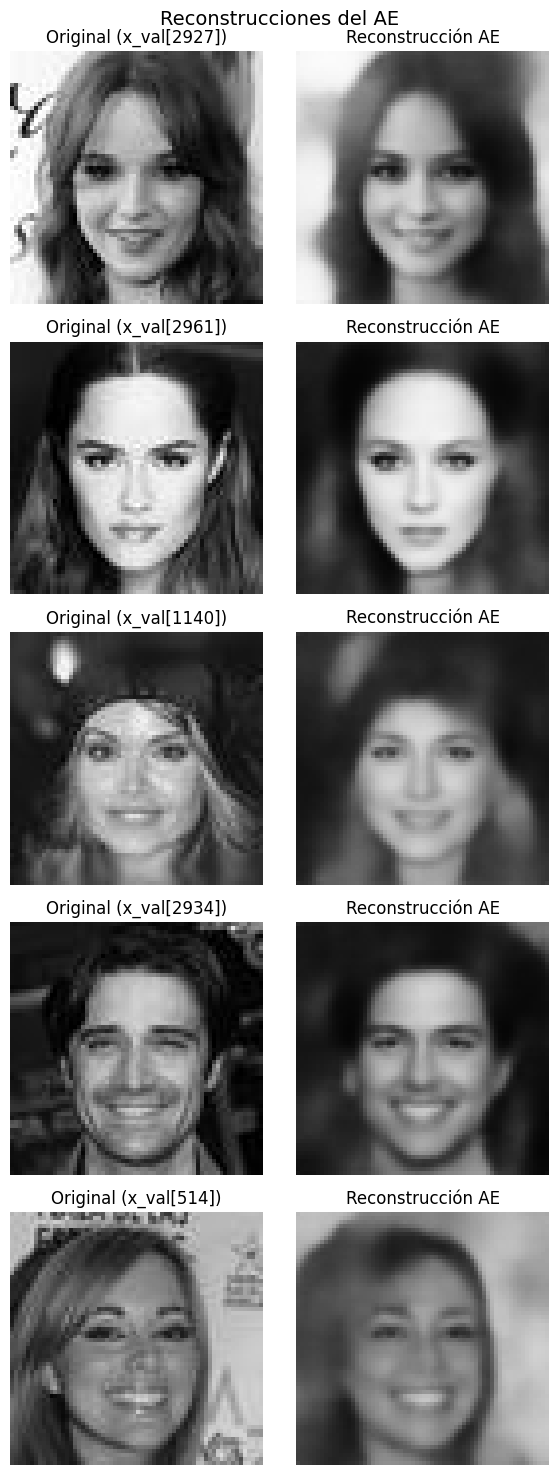

In [28]:
# Comparación de reconstrucciones del AE sobre cinco imágenes de validación
COMPARISON_SEED = SEED
comparison_rng = np.random.default_rng(COMPARISON_SEED)
comparison_indices = comparison_rng.choice(len(x_val), size=5, replace=False)
x_val_samples = x_val[comparison_indices]

z_val_samples = encoder_ae.predict(x_val_samples, verbose=0)
ae_reconstructions = decoder_ae.predict(z_val_samples, verbose=0)

fig, axes = plt.subplots(5, 2, figsize=(6, 15))
fig.suptitle("Reconstrucciones del AE", fontsize=14)

for row, (original, reconstruction, sample_index) in enumerate(
    zip(x_val_samples, ae_reconstructions, comparison_indices)
):
    axes[row, 0].imshow(original[..., 0], cmap="gray", vmin=0, vmax=1)
    axes[row, 0].set_title(f"Original (x_val[{sample_index}])")
    axes[row, 1].imshow(reconstruction[..., 0], cmap="gray", vmin=0, vmax=1)
    axes[row, 1].set_title("Reconstrucción AE")
    axes[row, 0].axis("off")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

In [22]:
# Mejores métricas obtenidas durante el entrenamiento
metrics_history = history_ae.history
best_epoch = int(np.argmin(metrics_history["val_loss"]))

print(f"Mejor época según val_loss: {best_epoch + 1}")
print(f"Train loss:      {metrics_history['loss'][best_epoch]:.4f}")
print(f"Validation loss: {metrics_history['val_loss'][best_epoch]:.4f}")

Mejor época según val_loss: 26
Train loss:      0.5302
Validation loss: 0.5309


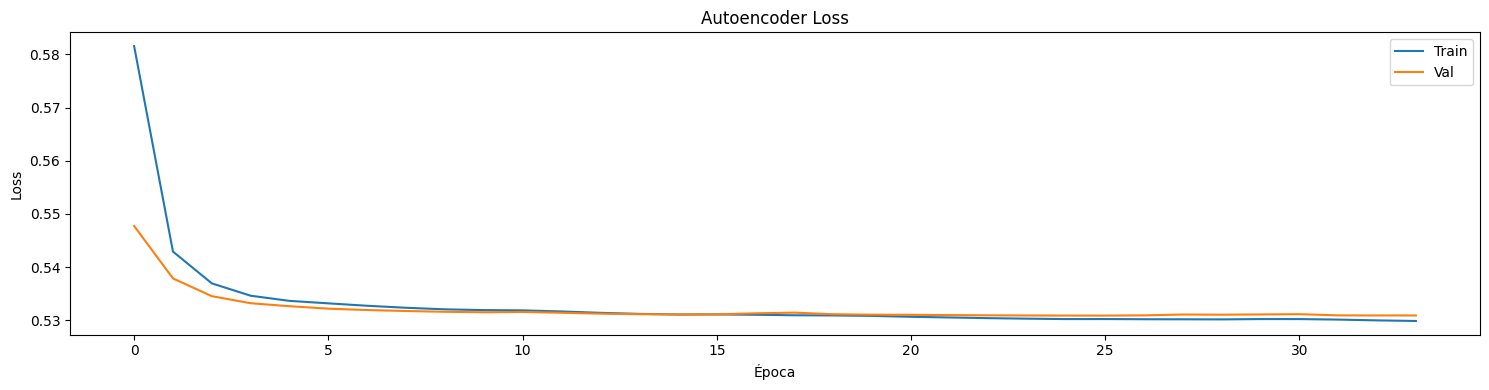

In [23]:
# Plot del entrenamiento
fig, axes = plt.subplots(1, figsize=(15, 4))

axes.plot(history_ae.history["loss"], label="Train")
axes.plot(history_ae.history["val_loss"], label="Val")
axes.set_title("Autoencoder Loss")
axes.set_xlabel("Época")
axes.set_ylabel("Loss")
axes.legend()

plt.tight_layout()
plt.show()

---

## **3. Creación de una submission**

In [24]:
import pandas as pd

In [25]:
# Muestreo de 200 vectores latentes para generar imágenes
N_SAMPLES = 200
LATENT_DIM = 64
SAMPLE_SEED = 1234

np.random.seed(SAMPLE_SEED)
z_samples = np.random.normal(
    loc=0.0,
    scale=1.0,
    size=(N_SAMPLES, LATENT_DIM)
).astype(np.float32)

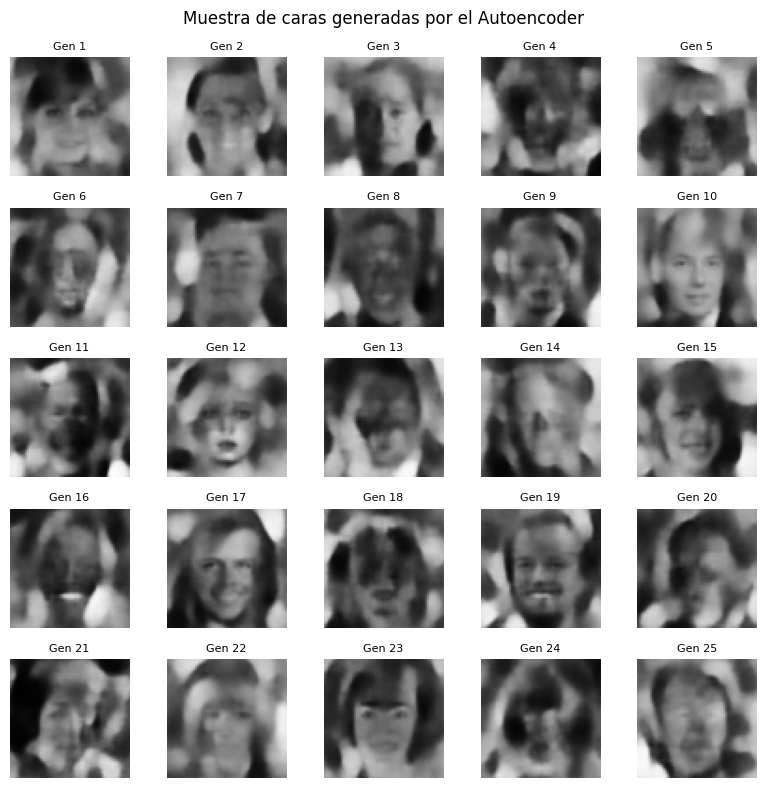

In [26]:
# Decodificación y conversión a uint8 [0, 255]
generated_imgs = decoder_ae.predict(
    z_samples,
    batch_size=N_SAMPLES,
    verbose=0
)

generated_imgs = np.clip(
    np.round(generated_imgs * 255.0), 0, 255
).astype(np.uint8)

generated_imgs = np.squeeze(generated_imgs, axis=-1)

fig, axes = plt.subplots(5, 5, figsize=(8, 8))
fig.suptitle("Muestra de caras generadas por el Autoencoder", fontsize=12)

for i, ax in enumerate(axes.flat):
    ax.imshow(generated_imgs[i], cmap="gray", vmin=0, vmax=255)
    ax.axis("off")
    ax.set_title(f"Gen {i + 1}", fontsize=8)

plt.tight_layout()
plt.show()

In [27]:
# Generación de la submission del Autoencoder
flat_pixels = generated_imgs.reshape(N_SAMPLES, IMG_SIZE * IMG_SIZE)

df_submission = pd.DataFrame(
    flat_pixels,
    columns=[str(i) for i in range(IMG_SIZE * IMG_SIZE)]
)

df_submission.insert(0, "Usage", "Public")
df_submission.insert(0, "ID", range(1, N_SAMPLES + 1))

csv_filename = "submission_ae.csv"
df_submission.to_csv(csv_filename, index=False)
print(f"Archivo guardado como '{csv_filename}'")

print(f"Forma esperada:  ({N_SAMPLES}, {IMG_SIZE * IMG_SIZE + 2})")
print(f"Forma obtenida:  {df_submission.shape}")
print(f"Rango de IDs:    {df_submission['ID'].min()} a {df_submission['ID'].max()}")
print(f"Valores únicos en 'Usage': {df_submission['Usage'].unique()}")
print(f"Primeras 5 columnas de cabecera: {list(df_submission.columns[:5])}")
print(f"Últimas 3 columnas de cabecera:  {list(df_submission.columns[-3:])}")
print(f"Valores nulos en el dataframe:   {df_submission.isnull().sum().sum()}")

Archivo guardado como 'submission_ae.csv'
Forma esperada:  (200, 4098)
Forma obtenida:  (200, 4098)
Rango de IDs:    1 a 200
Valores únicos en 'Usage': ['Public']
Primeras 5 columnas de cabecera: ['ID', 'Usage', '0', '1', '2']
Últimas 3 columnas de cabecera:  ['4093', '4094', '4095']
Valores nulos en el dataframe:   0


---

## **4. Evaluación FID del AE**

La FID compara imágenes reales de validación con imágenes generadas por el AE. Es la métrica usada en la competición.

In [29]:
%pip install "torchmetrics[image]"

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 3.2 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [torch-fidelity]m [torchmetrics]
Note: you may need to restart the kernel to use updated packages.


In [42]:
import torch
from torchmetrics.image.fid import FrechetInceptionDistance

FID_SEED = SEED
FID_BATCH_SIZE = 64
FID_NUM_IMAGES = min(len(x_val), 512)

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"


def prepare_images_for_fid(images):
    images = np.asarray(images)
    images = np.clip(images, 0.0, 1.0)
    images = (images * 255.0).round().astype(np.uint8)
    images = np.repeat(images, 3, axis=-1)
    images = np.transpose(images, (0, 3, 1, 2))
    return torch.from_numpy(images)


def calculate_fid(generated_images, real_images, batch_size=FID_BATCH_SIZE):
    fid = FrechetInceptionDistance(
        feature=2048,
        normalize=False
    ).to(device)

    real_images = prepare_images_for_fid(real_images)
    generated_images = prepare_images_for_fid(generated_images)

    with torch.inference_mode():
        for start in range(0, len(real_images), batch_size):
            fid.update(
                real_images[start:start + batch_size].to(device),
                real=True
            )

        for start in range(0, len(generated_images), batch_size):
            fid.update(
                generated_images[start:start + batch_size].to(device),
                real=False
            )

        return fid.compute().item()


real_images = x_val[:FID_NUM_IMAGES]
fid_rng = np.random.default_rng(FID_SEED)
train_indices_for_fid = fid_rng.choice(
    len(x_train),
    size=FID_NUM_IMAGES,
    replace=True
)
z_ae_fid = encoder_ae.predict(
    x_train[train_indices_for_fid],
    batch_size=FID_BATCH_SIZE,
    verbose=0
)
generated_ae_fid = decoder_ae.predict(
    z_ae_fid,
    batch_size=FID_BATCH_SIZE,
    verbose=0
)

device = torch.device("cpu")
fid_ae = calculate_fid(
    generated_ae_fid,
    real_images,
    batch_size=FID_BATCH_SIZE
)
print(f"FID AE ({FID_NUM_IMAGES} imágenes, dispositivo={device}): {fid_ae:.4f}")

FID AE (512 imágenes, dispositivo=cpu): 88.9463
